# 08 · Why was a month unusual? Rain, heat and El Niño

> **What and why**
>
> - A month with five times the normal fire needs an explanation. Most often it is the weather before it.
> - We bring NASA rain (GPM IMERG), weather (MERRA-2) and fire weather (GFWED) onto the same hexagons as the fires.
> - For every country and state with enough fire we measure how strongly fire follows a rain deficit and heat, and how El Niño moves the rain.
> - We score this on years the model never saw, so the app only explains where the explanation works.

In [1]:
import sys, os
from pathlib import Path
REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO)); sys.path.insert(0, str(REPO / 'style'))
import pandas as pd, numpy as np, duckdb, matplotlib.pyplot as plt
import fireharmony_style as fh
from fireharmony import config as C, features as FE
fh.use(); pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
FIG = REPO / 'report' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
con = C.connect()
import json
from matplotlib.colors import LogNorm, Normalize, TwoSlopeNorm
from fireharmony import climate as K, drivers as D
MODELS = REPO / 'models'
BORDERS = con.execute(f"SELECT ST_AsText(ST_Simplify(geom, 0.15)) AS w FROM ST_Read('{FE.ne_source('ne_10m_admin_0_countries')}')").df().w
dm = json.loads((MODELS / 'drivers.json').read_text())['areas']
mods = pd.DataFrame([{'kind': k.split(':', 1)[0], 'id': k.split(':', 1)[1], 'r2_cv': v['r2_cv'], 'uses_heat': 't2m_z' in v['terms'],
                      'beta_rain': v['beta']['rain3_z'], 'beta_heat': v['beta']['t2m_z'], 'enso_r': v['enso'].get('r'),
                      'enso_lag': v['enso'].get('lag'), 'fire_per_year': v['fire_per_year']} for k, v in dm.items()])
expl = pd.read_parquet(K.out('drivers_monthly.parquet'))
names = con.execute(f"SELECT kind, id, name FROM read_json_auto('{C.path('products') / 'v1.0' / 'areas.json'}')").df()
mods = mods.merge(names, on=['kind', 'id'], how='left')
print(f"{len(mods):,} areas with a driver model (at least {D.MIN_FIRE} hotspots a year)")

1,726 areas with a driver model (at least 300 hotspots a year)


## 1. The climate tables

Each raster was reduced once to level 3 hexagons (about 12,400 km2) and months, checked, and then deleted to save disk. A grid cell belongs to the hexagon that holds its centre, and a hexagon's value is the mean of its cells, weighted by their area.

In [2]:
rows = []
for name, col in [('rain_l3', 'rain_final_mm'), ('rain_l3', 'rain_late_mm'), ('merra2_l3', 't2m_c'), ('fwi_l3', 'fwi')]:
    r = con.execute(f'''SELECT count(*), count(DISTINCT hex), min(yr::INT * 100 + mo), max(yr::INT * 100 + mo)
                        FROM '{K.out(name + '.parquet')}' WHERE {col} IS NOT NULL''').fetchall()[0]
    rows.append({'table': name, 'variable': col, 'rows': r[0], 'hexagons': r[1], 'first month': r[2], 'last month': r[3]})
pd.DataFrame(rows)

,table,variable,rows,hexagons,first month,last month
0,rain_l3,rain_final_mm,4032141,13049,200001,202509
1,rain_l3,rain_late_mm,326225,13049,202410,202610
2,merra2_l3,t2m_c,4188729,13049,200001,202609
3,fwi_l3,fwi,2354408,10357,200201,202604


## 2. One rain record: bridging IMERG Late to IMERG Final

IMERG Final, which is corrected with rain gauges, ends in September 2025. After that only IMERG Late exists, which has no gauge correction. We downloaded a year where both exist (October 2024 to September 2025) and learned the ratio Final / Late for each hexagon, shrunk towards its continent, like the bridges between satellites. From October 2025 the rain is IMERG Late times that ratio.

In [3]:
kb = pd.read_parquet(K.out('rain_bridge.parquet'))
print(f"world ratio Final / Late: {kb[kb.months == 12].f.sum() / kb[kb.months == 12].l.sum():.3f}; "
      f"hexagons with a full overlap year: {(kb.months == 12).sum():,} of {len(kb):,}")
kb[kb.months == 12].groupby('continent').apply(lambda g: pd.Series({'Final / Late': round(g.f.sum() / g.l.sum(), 3),
    'hexagons, middle 90%': f"{g.k.quantile(0.05):.2f} to {g.k.quantile(0.95):.2f}"}), include_groups=False)

world ratio Final / Late: 0.947; hexagons with a full overlap year: 13,049 of 13,049


,Final / Late,"hexagons, middle 90%"
continent,,
Africa,0.883,0.73 to 1.03
Antarctica,0.811,0.81 to 0.85
Asia,0.982,0.77 to 1.35
Europe,1.011,0.85 to 1.30
North America,1.009,0.84 to 1.25
Oceania,0.935,0.75 to 1.05
Seven seas (open ocean),0.996,0.91 to 1.06
South America,0.884,0.71 to 1.09


## 3. Fire follows the rain: Central Kalimantan

Each dot is one month of 2002 to 2025. Across: the rain of that month and the 2 before, standardised (0 is normal, minus 2 is very dry). Up: fire against the normal of that month, on a log scale. Big dots are months of the fire season. The line is the fitted model.

,yr,mo,ratio,rain3_pct,f_rain,oni,oni_lagged,rain_z_from_enso
191237,2026,6,0.65,-27.780001,NaN,1.39,1.39,-1.28
191238,2026,7,3.20,-35.500000,9.820000,1.80,1.80,-1.66
191239,2026,8,6.05,-61.590000,30.950001,2.16,2.16,-2.00
191240,2026,9,5.14,-84.080002,52.970001,2.46,2.46,-2.27
191241,2026,10,13.83,-83.160004,54.910000,NaN,NaN,NaN


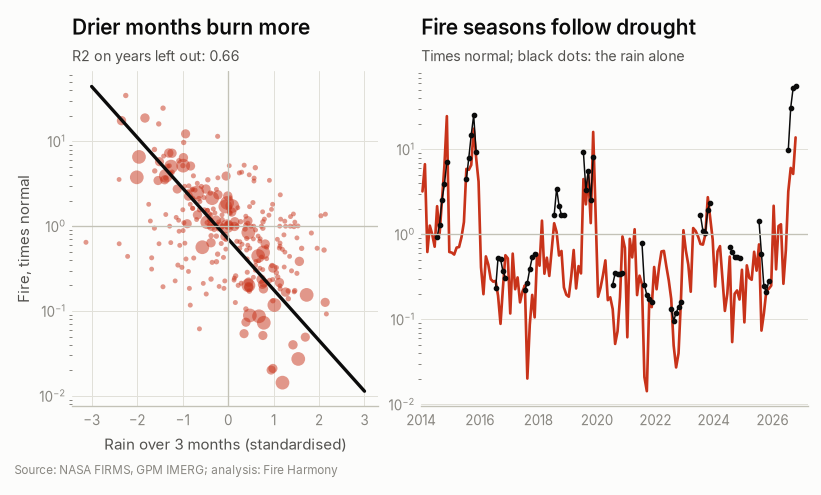

In [4]:
ck = expl[(expl.kind == 'state') & (expl.id == 'IDN-1931')]
m = dm['state:IDN-1931']
fit = ck[ck.yr.between(*D.FIT_YEARS)].dropna(subset=['rain3_z', 'ratio'])
fig, axes = plt.subplots(1, 2, figsize=fh.SIZE['full'], gridspec_kw={'width_ratios': [1.15, 1.45]})
ax = axes[0]
size = 8 + 60 * fit.normal / fit.normal.max()
ax.scatter(fit.rain3_z, fit.ratio.clip(lower=0.01), s=size, color=fh.EMBER[5], alpha=0.5, lw=0)
xs = np.linspace(-3, 3, 50)
ax.plot(xs, np.exp(m['beta']['const'] + m['beta']['rain3_z'] * xs), color=fh.INK, lw=2)
ax.set_yscale('log'); ax.axhline(1, color=fh.BASELINE, lw=0.8); ax.axvline(0, color=fh.BASELINE, lw=0.8)
ax.set_xlabel('Rain over 3 months (standardised)'); ax.set_ylabel('Fire, times normal')
fh.clean(ax, grid_axis='both')
fh.title(ax, 'Drier months burn more', f"R2 on years left out: {m['r2_cv']:.2f}")
ax = axes[1]
s2 = ck[ck.yr.between(2014, 2026)]
tt = s2.yr + (s2.mo - 0.5) / 12
ax.plot(tt, s2.ratio, color=fh.EMBER[5], lw=1.6)
ax.plot(tt, s2.f_drivers, color=fh.INK, lw=0.9, marker='o', ms=2.4)
ax.set_yscale('log'); ax.axhline(1, color=fh.BASELINE, lw=0.8)
ax.set_xlim(2014, 2027.2)
ax.xaxis.set_major_locator(plt.MultipleLocator(2)); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{int(v)}'))
fh.clean(ax)
fh.title(ax, 'Fire seasons follow drought', 'Times normal; black dots: the rain alone')
fh.source(fig, 'Source: NASA FIRMS, GPM IMERG; analysis: Fire Harmony')
fig.get_layout_engine().set(rect=(0, 0.035, 1, 1))
fh.save(fig, FIG / 'fig14_drivers_central_kalimantan')
ck[ck.yr.eq(2026) & ck.mo.between(6, 10)][['yr', 'mo', 'ratio', 'rain3_pct', 'f_rain', 'oni', 'oni_lagged', 'rain_z_from_enso']].round(2)

## 4. Where the weather explains fire

For every state with enough fire: the share of the ups and downs of fire that rain and heat explain, on years left out. Each level 3 hexagon takes the value of the state that holds most of its fire.

,count,25%,50%,75%
kind,,,,
continent,6.0,-0.005,0.052,0.103
country,148.0,-0.025,0.083,0.205
state,1571.0,-0.023,0.053,0.183
world,1.0,-0.041,-0.041,-0.041


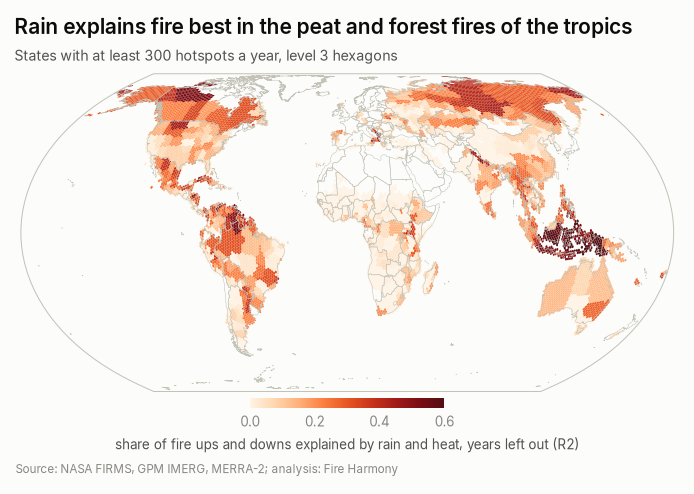

In [5]:
st = mods[mods.kind == 'state'].set_index('id')
w = pd.read_parquet(K.out('area_weights.parquet'))
w = w[w.kind == 'state'].sort_values('w').drop_duplicates('hex', keep='last')
w = w[w.id.isin(st.index)]
w['r2'] = w.id.map(st.r2_cv).clip(lower=0)
con.register('hw', w[['hex', 'r2']])
hx = con.execute("SELECT h3_cell_to_boundary_wkt(hex) AS wkt, r2 FROM hw").df()
fig, ax = plt.subplots(figsize=fh.SIZE['full'])
pc = fh.world_hexmap(ax, hx.wkt, hx.r2.to_numpy(), cmap='ember', norm=Normalize(0, 0.6), border_wkts=BORDERS)
cb = fig.colorbar(pc, ax=ax, fraction=0.03, pad=0.01, orientation='horizontal'); cb.outline.set_visible(False)
cb.set_label('share of fire ups and downs explained by rain and heat, years left out (R2)', color=fh.INK_2, fontsize=8)
fh.title(ax, 'Rain explains fire best in the peat and forest fires of the tropics', 'States with at least 300 hotspots a year, level 3 hexagons')
fh.source(fig, 'Source: NASA FIRMS, GPM IMERG, MERRA-2; analysis: Fire Harmony')
fh.save(fig, FIG / 'fig15_driver_skill_map')
q = mods.groupby('kind').r2_cv.describe(percentiles=[0.25, 0.5, 0.75])[['count', '25%', '50%', '75%']].round(3)
q

In [6]:
top = mods[(mods.kind == 'state') & (mods.fire_per_year > 3000)].nlargest(12, 'r2_cv')[['name', 'r2_cv', 'uses_heat', 'beta_rain', 'enso_r', 'enso_lag', 'fire_per_year']]
top.round(3)

,name,r2_cv,uses_heat,beta_rain,enso_r,enso_lag,fire_per_year
620,"Maluku, Indonesia",0.696,False,-0.696,-0.708,0,4186.5
765,"Kalimantan Selatan, Indonesia",0.691,False,-1.126,-0.753,0,11110.3
622,"Sulawesi Tenggara, Indonesia",0.658,False,-0.743,-0.723,0,4531.1
610,"Kalimantan Tengah, Indonesia",0.656,False,-1.378,-0.733,0,47422.7
770,"Sulawesi Selatan, Indonesia",0.626,False,-0.633,-0.722,0,3027.1
624,"Papua, Indonesia",0.624,False,-0.865,-0.641,0,13646.3
623,"Sulawesi Tengah, Indonesia",0.585,False,-0.593,-0.716,0,4526.8
760,"Kalimantan Barat, Indonesia",0.573,False,-0.657,-0.638,0,32614.9
1171,"Western, Papua New Guinea",0.571,False,-0.978,-0.591,1,7566.6
673,"Kalimantan Timur, Indonesia",0.557,False,-0.691,-0.739,0,15438.0


## 5. El Niño and the rain

El Niño does not light fires: it moves the rain. For each state we find the lag (0 to 6 months) at which El Niño moves its 3 month rain most, and the strength of that link.

,name,enso_r,enso_lag,r2_cv
23,Philippines,-0.798,3,0.532
68,Suriname,-0.684,1,0.539
148,Guyana,-0.672,1,0.550
164,Indonesia,-0.655,0,0.605
114,Trinidad and Tobago,-0.563,1,0.456
5,Malaysia,-0.562,0,0.234
113,Timor-Leste,-0.560,0,0.530
159,Venezuela,-0.554,1,0.494
26,Australia,-0.551,0,0.221
21,Panama,-0.529,0,0.373


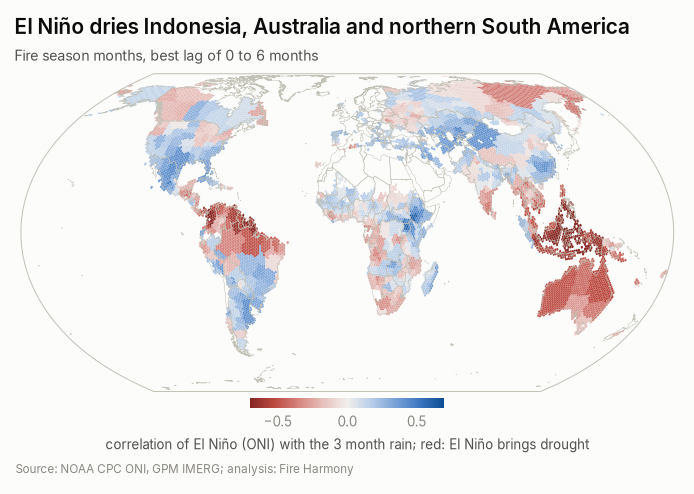

In [7]:
st2 = mods[mods.kind == 'state'].set_index('id')
w2 = pd.read_parquet(K.out('area_weights.parquet'))
w2 = w2[w2.kind == 'state'].sort_values('w').drop_duplicates('hex', keep='last')
w2 = w2[w2.id.isin(st2.index)]
w2['r'] = w2.id.map(st2.enso_r)
con.register('hw2', w2[['hex', 'r']])
hx2 = con.execute("SELECT h3_cell_to_boundary_wkt(hex) AS wkt, r FROM hw2").df()
fig, ax = plt.subplots(figsize=fh.SIZE['full'])
pc = fh.world_hexmap(ax, hx2.wkt, hx2.r.to_numpy(), cmap=fh.anomaly_cmap.reversed(), norm=TwoSlopeNorm(0, -0.7, 0.7), border_wkts=BORDERS)
cb = fig.colorbar(pc, ax=ax, fraction=0.03, pad=0.01, orientation='horizontal'); cb.outline.set_visible(False)
cb.set_label('correlation of El Niño (ONI) with the 3 month rain; red: El Niño brings drought', color=fh.INK_2, fontsize=8)
fh.title(ax, 'El Niño dries Indonesia, Australia and northern South America', 'Fire season months, best lag of 0 to 6 months')
fh.source(fig, 'Source: NOAA CPC ONI, GPM IMERG; analysis: Fire Harmony')
fh.save(fig, FIG / 'fig16_enso_rain_link')
mods[mods.kind == 'country'].dropna(subset=['enso_r']).nsmallest(10, 'enso_r')[['name', 'enso_r', 'enso_lag', 'r2_cv']].round(3)

> **Key findings**
>
> - On years the model never saw, rain and heat explain more than 20% of the ups and downs of fire in 23% of the 1,726 areas. In the median state they explain 5%: most monthly swings are not about the weather.
> - They work best where fire follows drought. Indonesian provinces fill the top of the list (Maluku 0.70, Kalimantan Selatan 0.69, Central Kalimantan 0.66, Papua 0.62), followed by Papua New Guinea and the north of the Amazon (Roraima 0.53).
> - In Central Kalimantan, one standard deviation less rain over three months means about four times more fire.
> - El Niño acts through the rain. Its link with the 3 month rain is r = -0.66 in Indonesia, -0.80 in the Philippines (three months later), and -0.56 and -0.55 in Malaysia and Australia.
> - In 2026 the three months to September brought 84% less rain than normal to Central Kalimantan, during a strong El Niño (ONI +2.46). Fire was 5 to 14 times normal from August to October.
> - In the driest months the simple model points to more fire than burned (October 2015: 25 times normal against 17.5). Fire grows less than the model says once almost everything that can burn is dry. So the app says more than 10 times normal there, not a number.
> - Heat is a real driver in boreal and temperate places such as Canada. In the tropics hot months come out with less fire, because thick smoke cools the surface, so heat is left out where that happens.
> - The fire estimate is given for months of the fire season only, and areas whose fire is mostly gas flares or lava on barren land (57 areas, such as Svalbard, Iceland's lava fields and the Algerian Sahara) get no model.
> - From October 2025 the rain comes from IMERG Late, bridged to IMERG Final with one ratio per hexagon (0.95 for the world, 0.88 for Africa and South America). IMERG Late changed version on 3 March 2026 after our bridge year. The 2026 rain looks like 2015 region by region (dry in the Maritime Continent and the north of South America, wet in East Africa in September and October), so we see no sign of a large version step, but a small bias is possible.